# SFT Troyer Category Analysis — By Diagnosis

Analyse Semantic Fluency Test (SFT) transcripts by mapping each spoken animal token to **Troyer categories** (from `Troyer_Animal_Categories.xlsx`), split by diagnosis group (HC, MCI, Dementia).

Each animal may have up to four overlapping Troyer labels. **Primary** analyses use `category1`; **multi-label** bar/stacked/heatmap analyses use all non-empty categories (exploded rows).

In [11]:
import sys
import re
from pathlib import Path
from difflib import get_close_matches

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from dataloader import TranscriptLoader

sns.set_theme(style="whitegrid")

DIAG_ORDER = ["HC", "MCI", "DEMENTIA"]
DIAG_COLORS = {"HC": "#2ca02c", "MCI": "#1f77b4", "DEMENTIA": "#d62728"}
DIAG_LABELS = {"HC": "Healthy", "MCI": "MCI", "DEMENTIA": "Dementia"}

BASE_DIR = Path.cwd()
TROYER_XLSX = BASE_DIR / "Troyer_Animal_Categories.xlsx"
UNIQUE_ANSWERS = BASE_DIR / "unique_sft_answers.csv"
OUT_CSV = BASE_DIR / "troyer_categories.csv"

CAT_COLS = ["category1", "category2", "category3", "category4"]

PREFIXES = (
    "black ", "brown ", "grizzly ", "polar ", "red ", "blue ", "grey ", "gray ", "snow ",
    "big ", "little ", "sea ", "water ", "orange ", "white ", "tiger ", "leopard ", "harrier ",
)

IRREGULAR_PLURAL = {
    "geese": "goose",
    "mice": "mouse",
    "teeth": "tooth",
    "feet": "foot",
    "oxen": "ox",
    "children": "child",
}


def normalize_key(s):
    if pd.isna(s) or s is None:
        return ""
    return str(s).strip().lower()


def strip_punct(s):
    s = re.sub(r"[^\w\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()


def answer_variants(raw):
    s = normalize_key(raw)
    out = []
    seen = set()

    def push(x):
        if not x:
            return
        x = x.strip()
        if x and x not in seen:
            seen.add(x)
            out.append(x)

    push(s)
    if s in IRREGULAR_PLURAL:
        push(IRREGULAR_PLURAL[s])
    sp = strip_punct(s)
    push(sp)
    nospace = "".join(sp.split())
    if nospace:
        push(nospace)
    if sp.endswith("s") and len(sp) > 2:
        push(sp[:-1])
        push("".join(sp[:-1].split()))
    if sp.endswith("?"):
        push(sp.rstrip("?").strip())
    for p in PREFIXES:
        if sp.startswith(p):
            push(sp[len(p):])
    for tok in sp.split():
        if len(tok) > 2:
            push(tok)
    return out


def build_troyer_lookup(troyer_df):
    lookup = {}
    for _, row in troyer_df.iterrows():
        k = normalize_key(row["response"])
        if k:
            lookup[k] = row
    return lookup


def match_troyer_row(raw, lookup, all_keys):
    for v in answer_variants(raw):
        if v in lookup:
            return lookup[v]
    for v in answer_variants(raw):
        if len(v) < 3:
            continue
        m = get_close_matches(v, all_keys, n=1, cutoff=0.72)
        if m:
            return lookup[m[0]]
    return None


def row_to_csv_cols(row):
    if row is None:
        return ["Unknown/Other", "", "", ""]
    out = []
    for c in CAT_COLS:
        v = row[c]
        if pd.isna(v) or str(v).strip() == "":
            out.append("")
        else:
            out.append(str(v).strip())
    if not out[0]:
        return ["Unknown/Other", "", "", ""]
    return out


# --- Generate troyer_categories.csv ---
troyer_df = pd.read_excel(TROYER_XLSX)
lookup = build_troyer_lookup(troyer_df)
all_keys = list(lookup.keys())

answers = pd.read_csv(UNIQUE_ANSWERS)["answer"].dropna().tolist()
rows_out = []
matched_n = 0
for ans in answers:
    mrow = match_troyer_row(ans, lookup, all_keys)
    cols = row_to_csv_cols(mrow)
    if mrow is not None:
        matched_n += 1
    rows_out.append([ans] + cols)

out_df = pd.DataFrame(rows_out, columns=["answer"] + CAT_COLS)
out_df.to_csv(OUT_CSV, index=False)
print(f"Wrote {OUT_CSV} ({len(out_df)} rows, {matched_n} matched to a Troyer animal)")

cat_df = pd.read_csv(OUT_CSV)

primary_lookup = dict(zip(cat_df["answer"], cat_df["category1"].fillna("Unknown/Other")))


def categories_from_csv_row(row):
    cats = []
    for c in CAT_COLS:
        v = row[c]
        if pd.isna(v) or str(v).strip() == "":
            continue
        cats.append(str(v).strip())
    return cats if cats else ["Unknown/Other"]


all_categories_lookup = {r["answer"]: categories_from_csv_row(r) for _, r in cat_df.iterrows()}
print(f"Loaded {len(primary_lookup)} primary mappings")
print("Sample Troyer labels:", sorted(set(c for lst in all_categories_lookup.values() for c in lst))[:15], "...")


Wrote /Users/bentindal/Desktop/CognoSpeak/animal analysis/troyer_categories.csv (406 rows, 315 matched to a Troyer animal)
Loaded 406 primary mappings
Sample Troyer labels: ['Africa', 'Arctic/ Far North', 'Asia', 'Australia', 'Beasts of Burden', 'Bird', 'Bovine', 'Canine', 'Deer', 'Farm', 'Feline', 'Fish', 'Fur', 'Insect', 'Insectivores'] ...


## Load SFT Transcripts and Merge Diagnosis Metadata

All available SFT transcripts are loaded so that each diagnosis group has a meaningful sample size.

In [12]:
loader = TranscriptLoader()
all_paths = loader.discover_transcript_files()

sft_paths = [p for p in all_paths if loader.infer_task_from_filename(p.name) == "SFT"]
print(f"Found {len(sft_paths)} SFT transcripts")

frames = [loader.load_transcript(p) for p in sft_paths]
df = pd.concat(frames, ignore_index=True)

metadata = loader.load_metadata()
df = loader.merge_with_metadata(df, metadata)

df["token_clean"] = df["token"].str.strip().str.lower()

df = df[df["diagnosis"].isin(DIAG_ORDER)].copy()
df["diagnosis"] = pd.Categorical(df["diagnosis"], categories=DIAG_ORDER, ordered=True)

print(f"\nTokens per diagnosis group:")
print(df.groupby("diagnosis", observed=True).agg(
    recordings=("recording", "nunique"),
    tokens=("token_clean", "count"),
))
df.head()


Found 91 SFT transcripts

Tokens per diagnosis group:
           recordings  tokens
diagnosis                    
HC                 40     939
MCI                30     590
DEMENTIA           20     334


,start_time,end_time,token,recording,task,recording_number,source_path,diagnosis,age,gender,MMSE,annotator,notes,metadata_recording_number,token_clean
0,4.444,5.188,cheetah,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,MCI,67.0,female,29.0,Mernan,"SFT: a lot of words said, quite big gap for on...",4,cheetah
1,5.82,6.692,lion,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,MCI,67.0,female,29.0,Mernan,"SFT: a lot of words said, quite big gap for on...",4,lion
2,7.292,8.388,panda,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,MCI,67.0,female,29.0,Mernan,"SFT: a lot of words said, quite big gap for on...",4,panda
3,9.596,11.076,panda,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,MCI,67.0,female,29.0,Mernan,"SFT: a lot of words said, quite big gap for on...",4,panda
4,14.588,15.448,elephant,Process-rec-004,SFT,4,/Users/bentindal/Desktop/CognoSpeak/data/Proce...,MCI,67.0,female,29.0,Mernan,"SFT: a lot of words said, quite big gap for on...",4,elephant


## Map Tokens to Troyer Categories

- `category` = primary (`category1`) for switching, pies, and temporal plots.
- `df_exploded` = one row per token–Troyer label pair for multi-label bar/stacked/heatmap analyses.

In [13]:
def all_cats_for_token(t):
    return all_categories_lookup.get(t, ["Unknown/Other"])


df["category"] = df["token_clean"].map(primary_lookup).fillna("Unknown/Other")
df["all_categories"] = df["token_clean"].map(all_cats_for_token)

df_exploded = (
    df.drop(columns=["category"])
    .explode("all_categories")
    .rename(columns={"all_categories": "category"})
)
df_exploded["category"] = df_exploded["category"].astype("string")

unmatched = df.loc[df["category"] == "Unknown/Other", "token_clean"].unique()
print(f"Primary Unknown/Other: {(df['category'] == 'Unknown/Other').sum()} / {len(df)} tokens")
if len(unmatched):
    print(f"Distinct tokens with Unknown primary ({len(unmatched)}): {list(unmatched[:20])}")

df[["recording", "diagnosis", "start_time", "token_clean", "category"]].head(15)


Primary Unknown/Other: 150 / 1863 tokens
Distinct tokens with Unknown primary (91): ['peacock', 'hummingbird', '?', 'sloth', 'cockerels', 'kittens', 'puppies', 'chihuahua', 'cormorant', 'flamingo', 'hippo', 'serpent', 'hound', 'umbrellabird', 'pigeons', 'snails', 'pigeon', 'cock', 'caterpillar', 'poochie']


,recording,diagnosis,start_time,token_clean,category
0,Process-rec-004,MCI,4.444,cheetah,Africa
1,Process-rec-004,MCI,5.82,lion,Africa
2,Process-rec-004,MCI,7.292,panda,Asia
3,Process-rec-004,MCI,9.596,panda,Asia
4,Process-rec-004,MCI,14.588,elephant,Africa
5,Process-rec-004,MCI,15.448,giraffe,Africa
6,Process-rec-004,MCI,17.596,springbok,Africa
7,Process-rec-004,MCI,18.844,zebra,Africa
8,Process-rec-004,MCI,20.284,rhinoceros,Africa
9,Process-rec-004,MCI,24.764,armadillo,Insectivores


## 1. Bar Chart — Troyer Category Distribution by Diagnosis (multi-label)

Grouped bars show the mean number of token–label pairs per recording in each Troyer category, split by diagnosis.

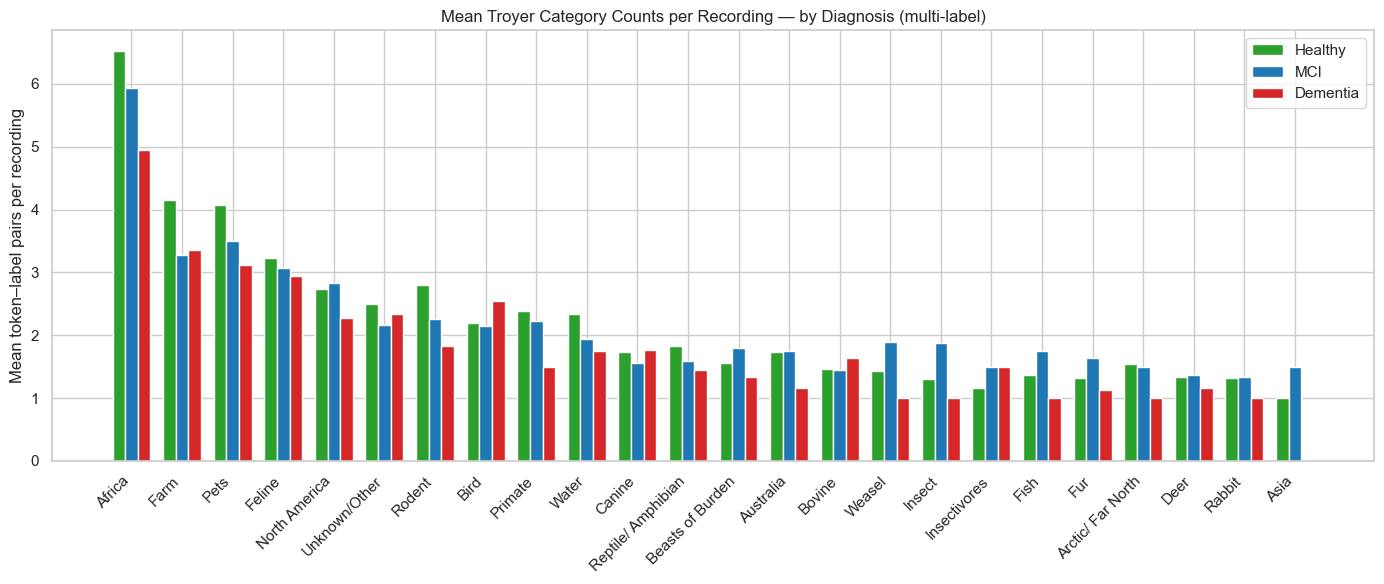

In [14]:
per_rec = (
    df_exploded.groupby(["diagnosis", "recording", "category"], observed=True)
    .size()
    .reset_index(name="count")
)
mean_counts = (
    per_rec.groupby(["diagnosis", "category"], observed=True)["count"]
    .mean()
    .reset_index(name="mean_count")
)

cat_order = (
    mean_counts.groupby("category")["mean_count"].sum()
    .sort_values(ascending=False).index.tolist()
)

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(cat_order))
width = 0.25

for i, diag in enumerate(DIAG_ORDER):
    subset = mean_counts[mean_counts["diagnosis"] == diag].set_index("category")
    vals = [subset.loc[c, "mean_count"] if c in subset.index else 0 for c in cat_order]
    ax.bar(x + i * width, vals, width, label=DIAG_LABELS[diag], color=DIAG_COLORS[diag])

ax.set_xticks(x + width)
ax.set_xticklabels(cat_order, rotation=45, ha="right")
ax.set_ylabel("Mean token–label pairs per recording")
ax.set_title("Mean Troyer Category Counts per Recording — by Diagnosis (multi-label)")
ax.legend()
plt.tight_layout()
plt.show()


## 2. Stacked Bar Chart — Troyer Categories per Recording (multi-label)

Each recording is broken down by Troyer labels (exploded).

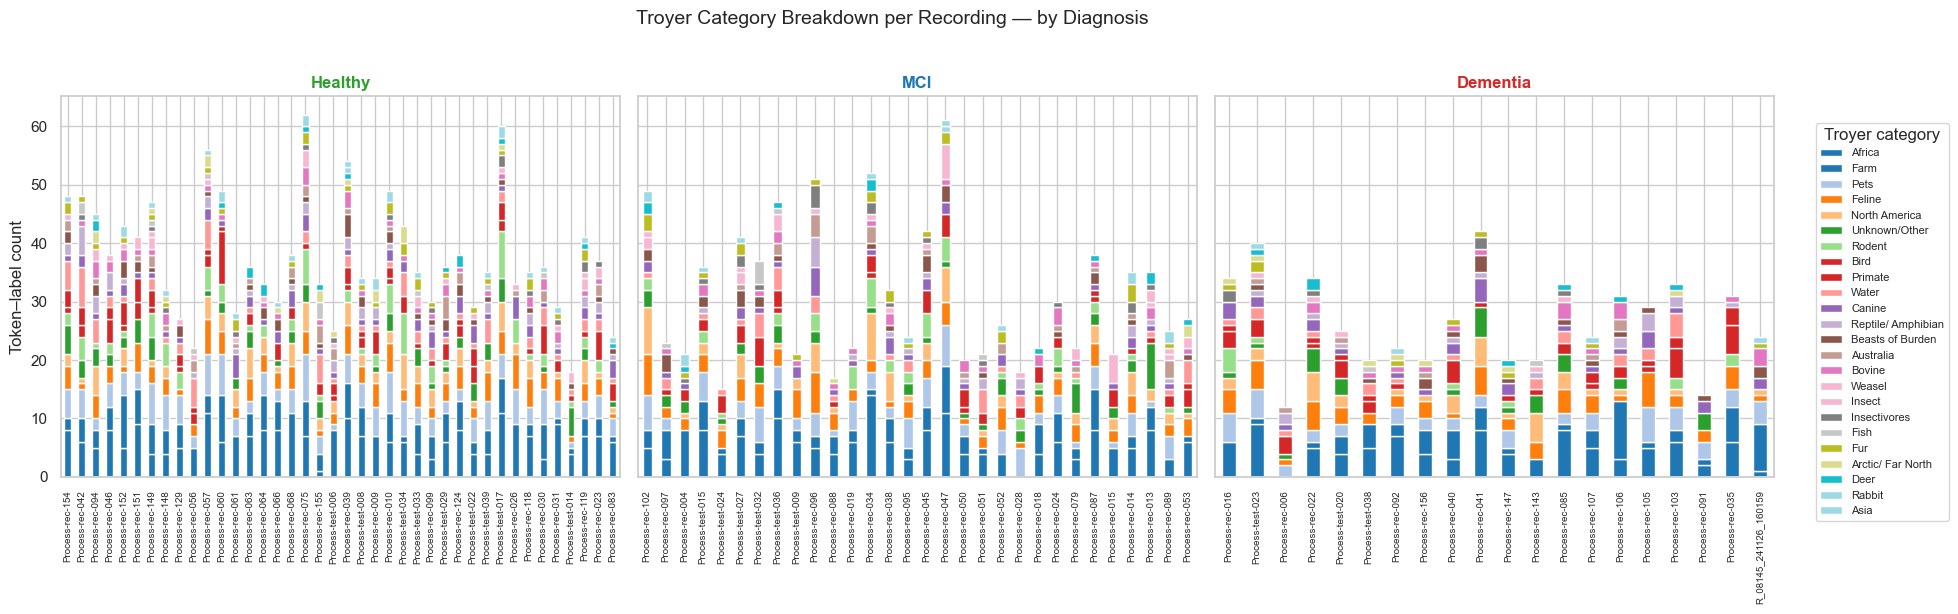

In [15]:
rec_diag = df_exploded.groupby("recording", observed=True)["diagnosis"].first()

cross = pd.crosstab(df_exploded["recording"], df_exploded["category"])
cross = cross.reindex(columns=cat_order, fill_value=0)
cross["diagnosis"] = cross.index.map(rec_diag)
cross = cross.sort_values("diagnosis")

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for ax, diag in zip(axes, DIAG_ORDER):
    group = cross[cross["diagnosis"] == diag].drop(columns="diagnosis")
    if group.empty:
        ax.set_title(f"{DIAG_LABELS[diag]} (no data)")
        continue
    group.plot.bar(stacked=True, ax=ax, colormap="tab20", legend=False)
    ax.set_title(DIAG_LABELS[diag], color=DIAG_COLORS[diag], fontweight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=90, labelsize=7)

axes[0].set_ylabel("Token–label count")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Troyer category", bbox_to_anchor=(1.01, 0.5), loc="center left", fontsize=8)
fig.suptitle("Troyer Category Breakdown per Recording — by Diagnosis", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


### Average Number of Distinct Troyer Categories per Participant — by Diagnosis

Counts unique Troyer labels (across all four columns) per recording.

Average distinct Troyer labels per participant:
           mean   std  count
Healthy   14.52  2.91     40
MCI       12.33  2.81     30
Dementia  11.80  2.65     20



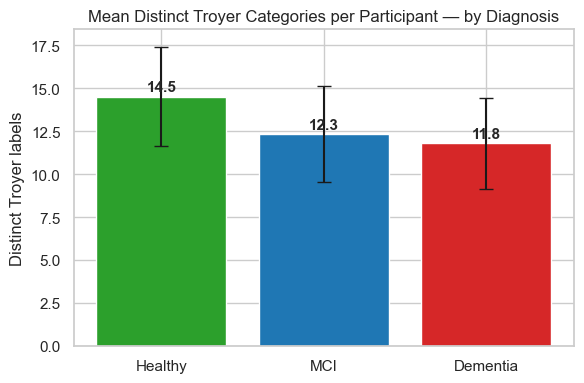

In [16]:
cats_per_rec = (
    df_exploded.groupby(["diagnosis", "recording"], observed=True)["category"]
    .nunique()
    .reset_index(name="n_categories")
)
avg_cats = (
    cats_per_rec.groupby("diagnosis", observed=True)["n_categories"]
    .agg(["mean", "std", "count"])
    .reindex(DIAG_ORDER)
)
avg_cats.index = [DIAG_LABELS[d] for d in avg_cats.index]
print("Average distinct Troyer labels per participant:")
print(avg_cats.round(2))
print()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    avg_cats.index,
    avg_cats["mean"],
    yerr=avg_cats["std"],
    capsize=5,
    color=[DIAG_COLORS[d] for d in DIAG_ORDER],
    edgecolor="white",
)
for bar, val in zip(bars, avg_cats["mean"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
            f"{val:.1f}", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylabel("Distinct Troyer labels")
ax.set_title("Mean Distinct Troyer Categories per Participant — by Diagnosis")
ax.set_ylim(0, avg_cats["mean"].max() + avg_cats["std"].max() + 1)
plt.tight_layout()
plt.show()


## 3. Troyer Category Proportion Heatmap — by Diagnosis (multi-label)


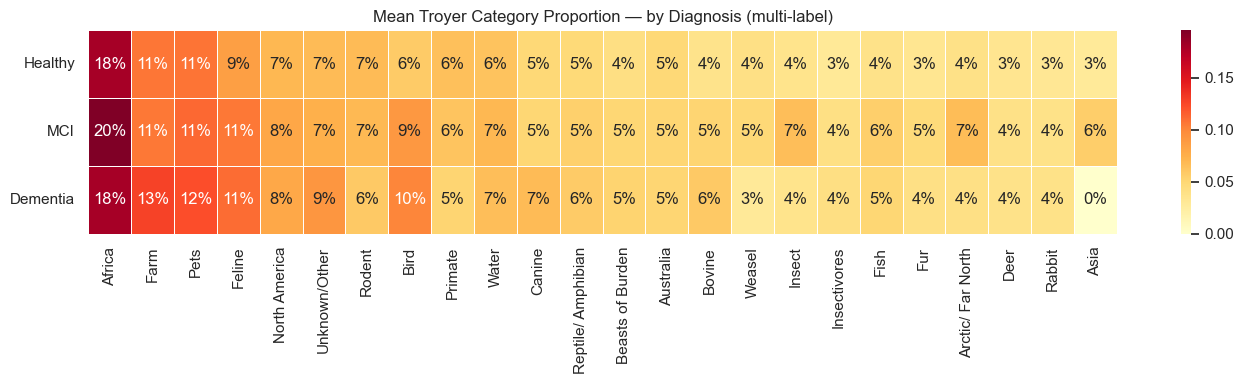

In [17]:
mean_props = (
    per_rec.assign(
        total=per_rec.groupby(["diagnosis", "recording"], observed=True)["count"].transform("sum")
    )
    .assign(prop=lambda x: x["count"] / x["total"])
    .groupby(["diagnosis", "category"], observed=True)["prop"]
    .mean()
    .reset_index()
    .pivot(index="diagnosis", columns="category", values="prop")
    .reindex(DIAG_ORDER)
    .fillna(0)
)
mean_props = mean_props[cat_order]
mean_props.index = [DIAG_LABELS[d] for d in mean_props.index]

fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(
    mean_props,
    annot=True,
    fmt=".0%",
    cmap="YlOrRd",
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Mean Troyer Category Proportion — by Diagnosis (multi-label)")
ax.set_ylabel("")
ax.set_xlabel("")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. Temporal Category Sequence — One per Diagnosis (primary category)

Each subplot shows a representative recording from each diagnosis group. Dots are coloured by primary Troyer category (`category1`).

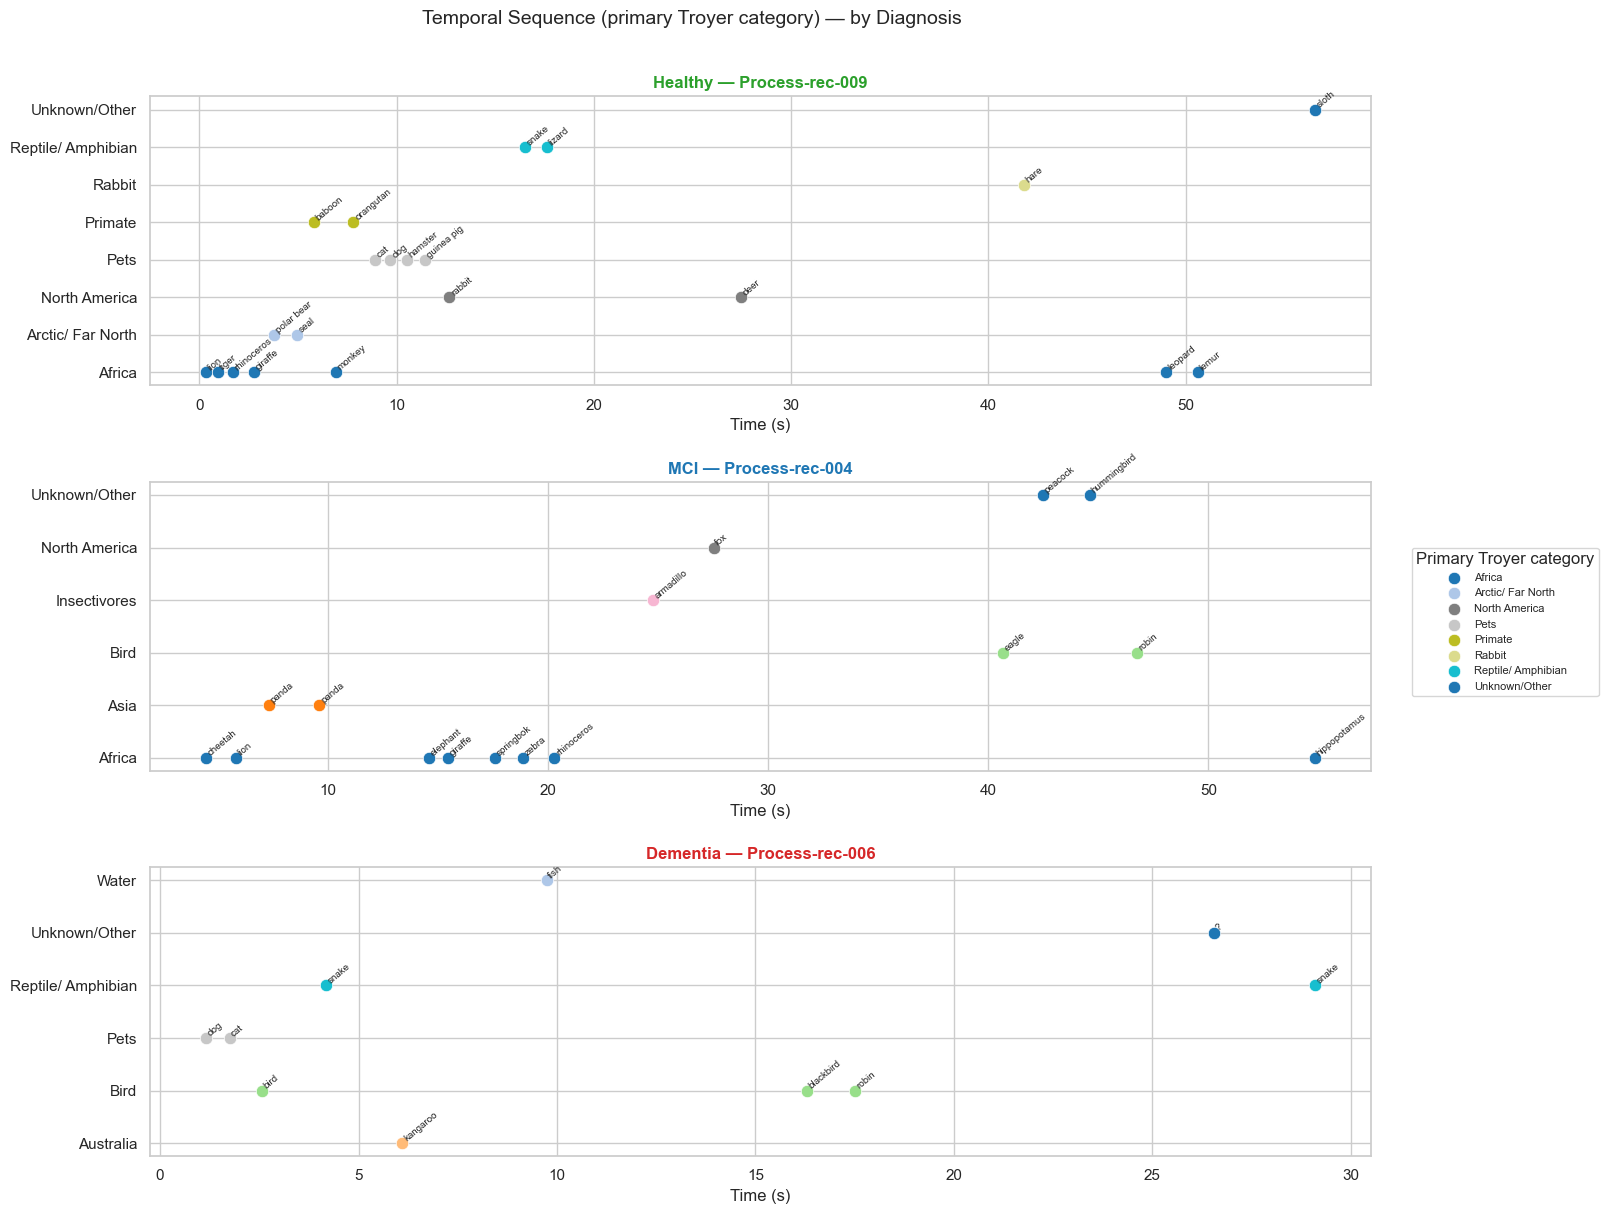

In [18]:
all_cats = sorted(df["category"].unique())
n_c = len(all_cats)
cat_palette = dict(zip(all_cats, sns.color_palette("tab20", max(n_c, 3))[:n_c]))

fig, axes = plt.subplots(len(DIAG_ORDER), 1, figsize=(14, 4 * len(DIAG_ORDER)), sharex=False)

for ax, diag in zip(axes, DIAG_ORDER):
    group_recs = df[df["diagnosis"] == diag]["recording"].unique()
    if len(group_recs) == 0:
        ax.set_title(f"{DIAG_LABELS[diag]} — no data")
        continue
    sample_rec = group_recs[0]
    sample = df[df["recording"] == sample_rec].sort_values("start_time").reset_index(drop=True)

    for cat in all_cats:
        mask = sample["category"] == cat
        if mask.sum() == 0:
            continue
        ax.scatter(
            sample.loc[mask, "start_time"],
            [cat] * mask.sum(),
            color=cat_palette[cat],
            s=80,
            label=cat,
            edgecolors="white",
            linewidth=0.5,
            zorder=3,
        )

    for _, row in sample.iterrows():
        ax.annotate(
            row["token_clean"],
            (row["start_time"], row["category"]),
            fontsize=7,
            rotation=40,
            ha="left",
            va="bottom",
        )

    ax.set_title(f"{DIAG_LABELS[diag]} — {sample_rec}", color=DIAG_COLORS[diag], fontweight="bold")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Primary Troyer category", bbox_to_anchor=(1.01, 0.5), loc="center left", fontsize=8)
fig.suptitle("Temporal Sequence (primary Troyer category) — by Diagnosis", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


## 5. Category Switching Analysis — by Diagnosis (primary category)

A *switch* occurs when consecutive tokens have different primary Troyer categories.

/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_89441/232991942.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_89441/232991942.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_89441/232991942.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([DIAG_LABELS[d] for d in DIAG_ORDER])
/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_89441/232991942.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will 

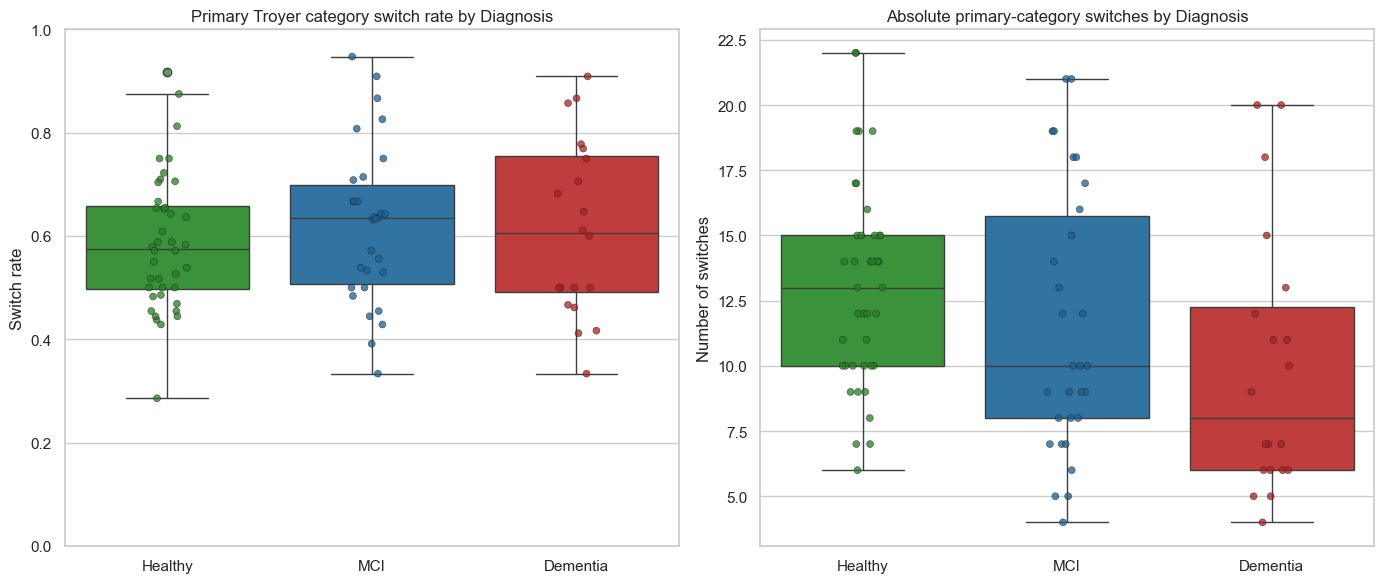

Mean switch rate per group:
               mean       std  count
diagnosis                           
Healthy    0.586982  0.131258     40
MCI        0.620571  0.152770     30
Dementia   0.613287  0.170036     20


In [19]:
def compute_switch_rate(group):
    group = group.sort_values("start_time")
    cats = group["category"].values
    if len(cats) < 2:
        return pd.Series({"switches": 0, "total_transitions": 0, "switch_rate": np.nan})
    switches = sum(a != b for a, b in zip(cats[:-1], cats[1:]))
    total = len(cats) - 1
    return pd.Series({"switches": switches, "total_transitions": total, "switch_rate": switches / total})

switch_df = (
    df.groupby("recording", observed=True)
    .apply(compute_switch_rate, include_groups=False)
    .reset_index()
)
switch_df["diagnosis"] = switch_df["recording"].map(
    df.groupby("recording", observed=True)["diagnosis"].first()
)
switch_df["diagnosis"] = pd.Categorical(switch_df["diagnosis"], categories=DIAG_ORDER, ordered=True)

import colorsys
from matplotlib.colors import to_rgb

def _darken(color, amount=0.85):
    r, g, b = to_rgb(color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    l = max(0, min(1, l * amount))
    return colorsys.hls_to_rgb(h, l, s)

_strip_palette = {d: _darken(DIAG_COLORS[d], amount=0.80) for d in DIAG_ORDER}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(
    data=switch_df, x="diagnosis", y="switch_rate",
    order=DIAG_ORDER, palette=DIAG_COLORS, ax=axes[0],
)
sns.stripplot(
    data=switch_df, x="diagnosis", y="switch_rate",
    order=DIAG_ORDER, palette=_strip_palette, ax=axes[0],
    size=5, alpha=0.75, jitter=True,
    edgecolor="#222", linewidth=0.4,
)
axes[0].set_xticklabels([DIAG_LABELS[d] for d in DIAG_ORDER])
axes[0].set_ylabel("Switch rate")
axes[0].set_xlabel("")
axes[0].set_title("Primary Troyer category switch rate by Diagnosis")
axes[0].set_ylim(0, 1)

sns.boxplot(
    data=switch_df, x="diagnosis", y="switches",
    order=DIAG_ORDER, palette=DIAG_COLORS, ax=axes[1],
)
sns.stripplot(
    data=switch_df, x="diagnosis", y="switches",
    order=DIAG_ORDER, palette=_strip_palette, ax=axes[1],
    size=5, alpha=0.75, jitter=True,
    edgecolor="#222", linewidth=0.4,
)
axes[1].set_xticklabels([DIAG_LABELS[d] for d in DIAG_ORDER])
axes[1].set_ylabel("Number of switches")
axes[1].set_xlabel("")
axes[1].set_title("Absolute primary-category switches by Diagnosis")

plt.tight_layout()
plt.show()

print("Mean switch rate per group:")
print(switch_df.groupby("diagnosis", observed=True)["switch_rate"].agg(["mean", "std", "count"]).rename(
    index=DIAG_LABELS
))


## 6. Pie Charts — Primary Troyer Category Proportions by Diagnosis


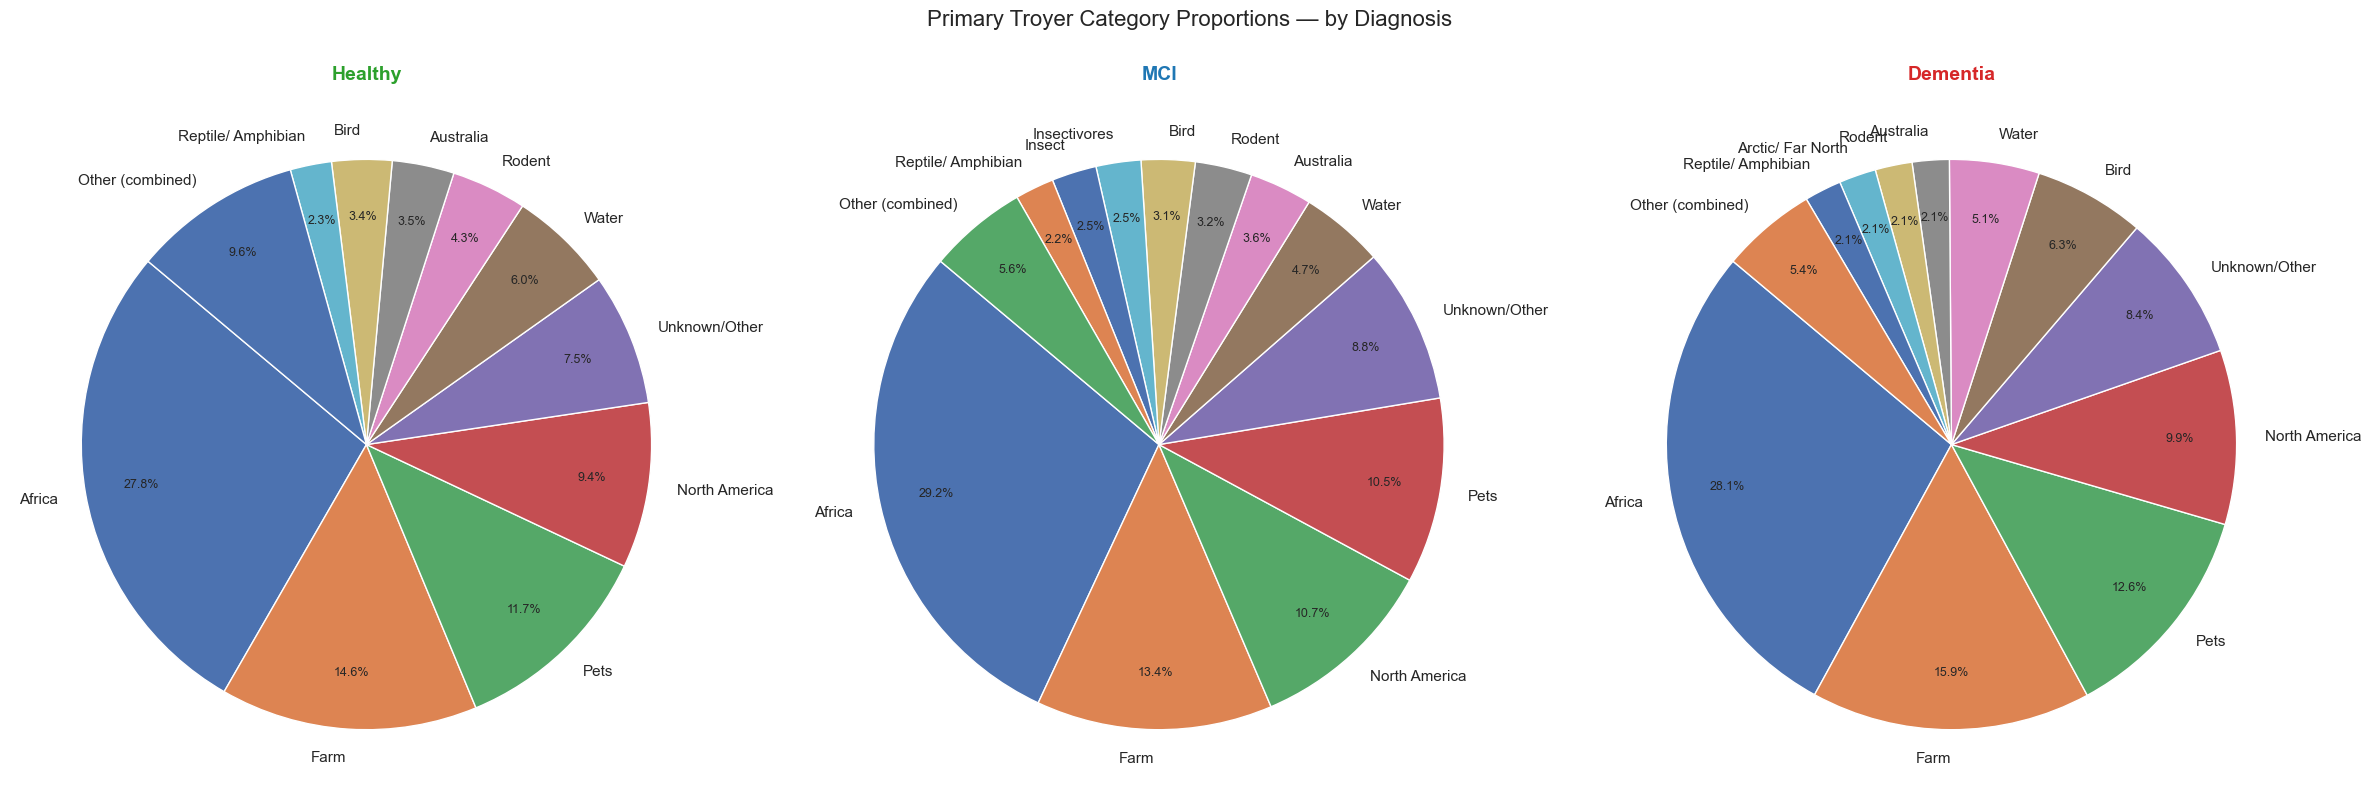

In [20]:
fig, axes = plt.subplots(1, len(DIAG_ORDER), figsize=(8 * len(DIAG_ORDER), 8))

for ax, diag in zip(axes, DIAG_ORDER):
    sub = df[df["diagnosis"] == diag]
    if sub.empty:
        ax.set_title(f"{DIAG_LABELS[diag]} — no data")
        continue
    cat_totals = sub["category"].value_counts()

    threshold = 0.02 * len(sub)
    main_cats = cat_totals[cat_totals >= threshold].copy()
    other_sum = cat_totals[cat_totals < threshold].sum()
    if other_sum > 0:
        main_cats["Other (combined)"] = other_sum

    wedges, texts, autotexts = ax.pie(
        main_cats,
        labels=main_cats.index,
        autopct="%1.1f%%",
        startangle=140,
        pctdistance=0.8,
    )
    for t in autotexts:
        t.set_fontsize(9)
    ax.set_title(DIAG_LABELS[diag], color=DIAG_COLORS[diag], fontweight="bold", fontsize=14)

fig.suptitle("Primary Troyer Category Proportions — by Diagnosis", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


## 7. Max consecutive streak (primary Troyer category)

Within each recording, tokens are ordered by `start_time`. A **streak** is a run of consecutive tokens with the same primary `category` (same definition as switching). **Max streak** is the longest such run in that recording, and **streak category** is which label achieved that maximum.

Group sizes: HC *n*=40, MCI *n*=30, Dementia *n*=20 — interpret the smallest group with wider uncertainty.

/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_89441/275266881.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_89441/275266881.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/var/folders/ll/3tyvzctx1372nslqytmh85100000gn/T/ipykernel_89441/275266881.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(_xtlabs)


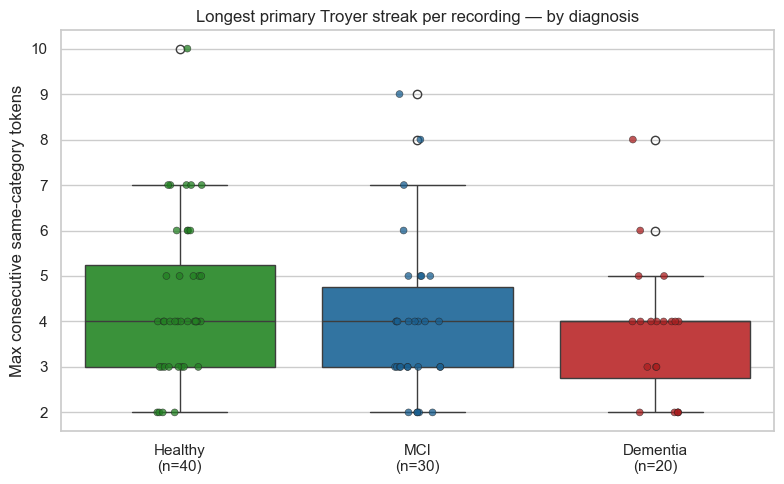

Max streak per recording (summary):
            mean    std  median  count
diagnosis                             
Healthy    4.450  1.739     4.0     40
MCI        3.967  1.732     4.0     30
Dementia   3.750  1.517     4.0     20

Most common streak category at the max (per recording, by diagnosis):

Healthy (n=40):
streak_category
Africa           24
Farm             10
Pets              3
Water             2
Unknown/Other     1
Name: count, dtype: int64

MCI (n=30):
streak_category
Africa           19
Farm              4
Pets              3
North America     2
Insect            1
Unknown/Other     1
Name: count, dtype: int64

Dementia (n=20):
streak_category
Africa           14
Farm              3
Pets              2
North America     1
Name: count, dtype: int64


In [21]:
def max_streak_per_recording(group):
    group = group.sort_values("start_time")
    cats = group["category"].values
    if len(cats) == 0:
        return pd.Series({"max_streak": np.nan, "streak_category": np.nan})
    max_run = 1
    cur_run = 1
    streak_cat_at_max = cats[0]
    for i in range(1, len(cats)):
        if cats[i] == cats[i - 1]:
            cur_run += 1
        else:
            cur_run = 1
        if cur_run > max_run:
            max_run = cur_run
            streak_cat_at_max = cats[i]
    return pd.Series({"max_streak": max_run, "streak_category": streak_cat_at_max})


streak_df = (
    df.groupby("recording", observed=True)
    .apply(max_streak_per_recording, include_groups=False)
    .reset_index()
)
streak_df["diagnosis"] = streak_df["recording"].map(
    df.groupby("recording", observed=True)["diagnosis"].first()
)
streak_df["diagnosis"] = pd.Categorical(streak_df["diagnosis"], categories=DIAG_ORDER, ordered=True)

# Reuse strip styling from switching cell if present; else define locally
try:
    _sp = _strip_palette
except NameError:
    import colorsys
    from matplotlib.colors import to_rgb

    def _darken(color, amount=0.85):
        r, g, b = to_rgb(color)
        h, l, s = colorsys.rgb_to_hls(r, g, b)
        l = max(0, min(1, l * amount))
        return colorsys.hls_to_rgb(h, l, s)

    _sp = {d: _darken(DIAG_COLORS[d], amount=0.80) for d in DIAG_ORDER}

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=streak_df,
    x="diagnosis",
    y="max_streak",
    order=DIAG_ORDER,
    palette=DIAG_COLORS,
    ax=ax,
)
sns.stripplot(
    data=streak_df,
    x="diagnosis",
    y="max_streak",
    order=DIAG_ORDER,
    palette=_sp,
    ax=ax,
    size=5,
    alpha=0.75,
    jitter=True,
    edgecolor="#222",
    linewidth=0.4,
)
_counts = streak_df.groupby("diagnosis", observed=True).size()
_xtlabs = [f"{DIAG_LABELS[d]}\n(n={int(_counts.get(d, 0))})" for d in DIAG_ORDER]
ax.set_xticklabels(_xtlabs)
ax.set_ylabel("Max consecutive same-category tokens")
ax.set_xlabel("")
ax.set_title("Longest primary Troyer streak per recording — by diagnosis")

plt.tight_layout()
plt.show()

print("Max streak per recording (summary):")
print(
    streak_df.groupby("diagnosis", observed=True)["max_streak"]
    .agg(["mean", "std", "median", "count"])
    .rename(index=DIAG_LABELS)
    .round(3)
)

print("\nMost common streak category at the max (per recording, by diagnosis):")
for d in DIAG_ORDER:
    sub = streak_df[streak_df["diagnosis"] == d]["streak_category"]
    print(f"\n{DIAG_LABELS[d]} (n={len(sub)}):")
    print(sub.value_counts().head(8))